# Unidad IV — Análisis no supervisado

**Estudiante:** Kevin Hernández Trejo · **Matrícula:** 23300950 · **Grupo:** 10IDGS-G1  
**Proyecto:** Clasificación automática y análisis morfológico de variedades de frijol

Objetivo: descubrir agrupaciones naturales sin utilizar `Class` para entrenar. Se aplica estandarización, PCA, K-means, método del codo y coeficiente de silueta.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.modelos_no_supervisados import ejecutar_modelado_no_supervisado
print('Raíz del proyecto:', ROOT)

Raíz del proyecto: C:\Users\crepe\Documents\Proyectos\REC_ECBD_2026_Hernandez_Trejo_Kevin


## 1. Ejecutar el análisis completo

Esta celda trabaja con el dataset procesado. `Class` queda excluida de las variables de entrada de K-means y solo se utiliza al final como referencia interpretativa.

In [2]:
%cd $ROOT
resumen = ejecutar_modelado_no_supervisado()

C:\Users\crepe\Documents\Proyectos\REC_ECBD_2026_Hernandez_Trejo_Kevin
ANALISIS NO SUPERVISADO: STANDARD SCALER + PCA + K-MEANS


k= 2 | Inercia=   118560.30 | Silhouette=0.4110


k= 3 | Inercia=    84724.44 | Silhouette=0.4203


k= 4 | Inercia=    66991.24 | Silhouette=0.3605


k= 5 | Inercia=    53127.26 | Silhouette=0.3775


k= 6 | Inercia=    46750.88 | Silhouette=0.3793


k= 7 | Inercia=    41015.44 | Silhouette=0.3289


k= 8 | Inercia=    37822.45 | Silhouette=0.3207


k= 9 | Inercia=    35485.87 | Silhouette=0.3075


k=10 | Inercia=    33346.87 | Silhouette=0.2951



Mejor k segun silhouette: 3
Componentes PCA para >=90% de varianza: 4
ARI=0.2964 | NMI=0.4837
ANALISIS NO SUPERVISADO FINALIZADO


## 2. ¿Por qué estandarizar?

Las variables tienen escalas diferentes. `Area` puede medir decenas de miles y otras variables están entre cero y uno. `StandardScaler` evita que las variables de mayor magnitud dominen las distancias de K-means.

In [3]:
evaluacion_k = pd.DataFrame(resumen['evaluacion_k'])
evaluacion_k

,k,inercia,silhouette
0,2,118560.303822,0.410971
1,3,84724.435859,0.420258
2,4,66991.241498,0.360500
3,5,53127.259898,0.377475
4,6,46750.879924,0.379274
5,7,41015.440580,0.328876
6,8,37822.450919,0.320665
7,9,35485.873704,0.307489
8,10,33346.865697,0.295128


## 3. Selección del número de grupos

- **Inercia:** suma de distancias internas; disminuye al aumentar `k`. Se busca un codo.
- **Silhouette:** combina cohesión y separación; cuanto más cerca de 1, mejor.
- Se selecciona el `k` con mayor silhouette entre 2 y 10. Esto es una decisión basada en los datos, no en conocer previamente las siete clases.

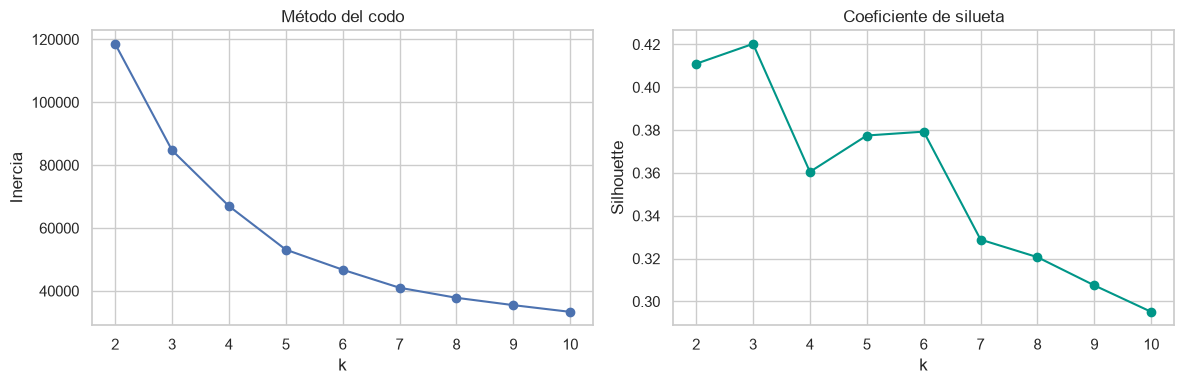

Mejor k: 3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(evaluacion_k['k'], evaluacion_k['inercia'], marker='o')
axes[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
axes[1].plot(evaluacion_k['k'], evaluacion_k['silhouette'], marker='o', color='#009688')
axes[1].set(title='Coeficiente de silueta', xlabel='k', ylabel='Silhouette')
plt.tight_layout(); plt.show()
print('Mejor k:', resumen['mejor_k_segun_silhouette'])

## 4. PCA

PCA transforma las variables correlacionadas en componentes que concentran la información. Aquí se conservan los componentes necesarios para explicar al menos 90 % de la varianza; los dos primeros permiten visualizar los grupos.

In [5]:
df_cluster = pd.read_csv(ROOT / 'data/processed/dry_beans_clustered.csv')
print('Componentes para >=90%:', resumen['componentes_pca_para_90_por_ciento'])
print('Varianza acumulada:', f"{resumen['varianza_explicada_acumulada']:.2%}")
df_cluster[['PC1','PC2','Cluster','Class']].head()

Componentes para >=90%: 4
Varianza acumulada: 95.00%


,PC1,PC2,Cluster,Class
0,-4.972914,1.826356,1,SEKER
1,-5.429075,2.937605,1,SEKER
2,-4.749514,1.828627,1,SEKER
3,-4.289936,2.003728,1,SEKER
4,-6.343428,4.095577,1,SEKER


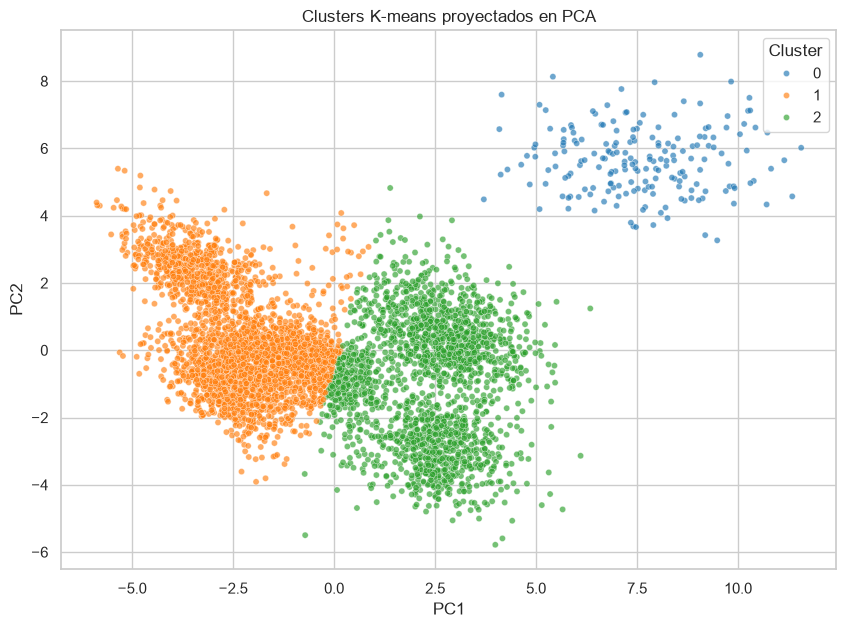

In [6]:
muestra = df_cluster.sample(5000, random_state=42)
plt.figure(figsize=(10,7))
sns.scatterplot(data=muestra, x='PC1', y='PC2', hue='Cluster', palette='tab10', s=20, alpha=.65)
plt.title('Clusters K-means proyectados en PCA'); plt.show()

## 5. Comparación interpretativa con las clases

La tabla cruzada **no entrena** el algoritmo. Sirve para observar qué variedades aparecen dentro de cada grupo. ARI y NMI comparan ambas particiones; valores moderados indican que los grupos morfológicos no equivalen exactamente a las etiquetas botánicas.

In [7]:
tabla = pd.crosstab(df_cluster['Cluster'], df_cluster['Class'])
display(tabla)
display(pd.DataFrame([resumen['comparacion_externa_solo_interpretativa']]))

Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,,
0,1,522,1,0,0,0,0
1,118,0,7,3503,17,2021,1905
2,1203,0,1622,43,1843,6,731


,ARI,NMI
0,0.296397,0.483651


## Conclusión

K-means encontró grupos naturales basados exclusivamente en características numéricas. El mejor `k` se eligió por silhouette. Que el resultado no sea necesariamente siete es válido: una clase botánica puede compartir forma con otra y una misma variedad puede contener variación morfológica. El agrupamiento complementa la clasificación supervisada, pero no la sustituye.